# PREDICCION DEL NO2 HASTA 2030

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
spark.sql ("SHOW TABLES in gold").show()

ivysettings.xml file not found in HIVE_HOME or HIVE_CONF_DIR,/etc/hive/conf.dist/ivysettings.xml will be used


+---------+----------------+-----------+
|namespace|       tableName|isTemporary|
+---------+----------------+-----------+
|     gold|            aire|      false|
|     gold|dim_contaminante|      false|
|     gold|    dim_distrito|      false|
|     gold|      dim_espira|      false|
|     gold|    dim_estacion|      false|
|     gold|   dim_sonometro|      false|
|     gold|      dim_tiempo|      false|
|     gold|       fact_aire|      false|
|     gold|      fact_meteo|      false|
|     gold|  fact_poblacion|      false|
|     gold| fact_prediccion|      false|
|     gold|      fact_ruido|      false|
|     gold|    fact_trafico|      false|
|     gold| fact_zona_verde|      false|
+---------+----------------+-----------+



## 1. NO2 medio anual

In [3]:
anual = spark.sql ("""
    SELECT t.anio, 
    ROUND(AVG(a.concentracion),1) AS no2_medio
    FROM gold.fact_aire a
    JOIN gold.dim_tiempo t 
        ON a.id_tiempo = t.id_tiempo
    JOIN gold.dim_contaminante c 
        ON a.id_contaminante = c.id_contaminante
        WHERE c.nombre = 'NO2'
        AND t.anio <= 2025
    GROUP by t.anio
    ORDER BY t.anio
    """).toPandas()

anual

,anio,no2_medio
0,2013,30.7
1,2014,28.5
2,2015,32.0
3,2016,28.9
4,2017,29.8
5,2018,26.6
6,2019,24.9
7,2020,19.0
8,2021,16.2
9,2022,17.1


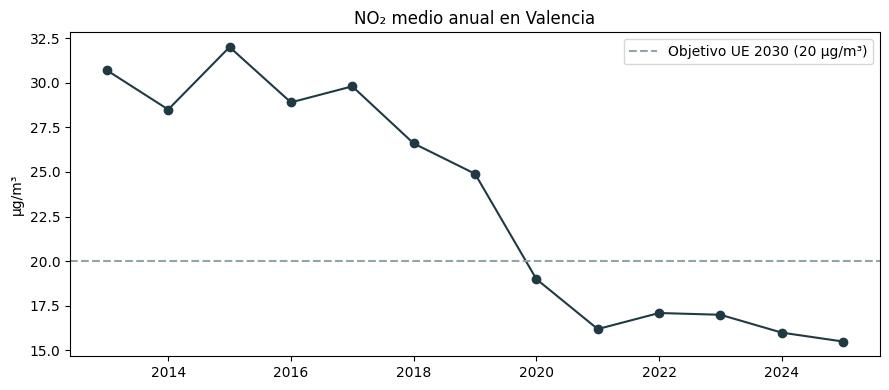

In [4]:
import io
import matplotlib.pyplot as plt
from google.cloud import storage

plt.figure(figsize=(9, 4))
plt.plot(anual["anio"], anual["no2_medio"], marker="o", color="#203A43")
plt.axhline(20, color="#8FA5A8", linestyle="--", label="Objetivo UE 2030 (20 µg/m³)")
plt.title("NO₂ medio anual en Valencia")
plt.ylabel("µg/m³")
plt.legend()
plt.tight_layout()

# Guardar en el bucket
buffer = io.BytesIO()
plt.savefig(buffer, format="png", dpi=300, bbox_inches="tight")

bucket = storage.Client().bucket("tfm_unir1")
bucket.blob("processed/figuras/no2_evolucion_anual.png").upload_from_string(
    buffer.getvalue(), content_type="image/png")

plt.show()

Como 2020 marca un punto de inflexión y desde ese momento no ha aumentado el NO2, conviene hacer nuestras proyecciones desde 2021. De lo contrario el modelo podría interpretar que esa caída se dará cada año y puede que la predicción no sea certera.

## 2. Modelo base: regresión lineal (2021-2025)

In [5]:
from sklearn.linear_model import LinearRegression

# Datos de entrenamiento: desde el año 2021
datos = anual[anual["anio"]>= 2021]

# Entrenamos el modelo: aprende cómo cmabia el NO2 según el año
modelo_lineal = LinearRegression()
modelo_lineal.fit(datos[["anio"]], datos["no2_medio"])

print ("Cambio por año:", round(modelo_lineal.coef_[0],2), "µg/m³")

# Predecimos de 2026 a 2030
futuro = pd.DataFrame({"anio": range(2026, 2031)})
futuro["no2_previsto"] = modelo_lineal.predict(futuro[["anio"]]).round(1)

futuro

/opt/conda/miniconda3/lib/python3.10/site-packages/scipy/__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.26.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Cambio por año: -0.25 µg/m³


,anio,no2_previsto
0,2026,15.6
1,2027,15.4
2,2028,15.1
3,2029,14.9
4,2030,14.6


Este simple modelo indica que en 2030 el NO2 estaría en 14.6.
Para comprobar este modelo, vamos a evaluarlo con entrenamiento y test tomando los años del 2021 al 2024 como train y 2025 como test.
Son pocos datos, pero es una primera aproximación

### Evaluación del modelo base

In [6]:
from sklearn.metrics import mean_absolute_error

# Entrenamos solo con 2021-2024 y dejamos 2025 para probar

train_anual = anual[(anual["anio"]>=2021) & (anual["anio"]<=2024)]
test_anual  = anual[anual["anio"]==2025]

modelo_test = LinearRegression()
modelo_test.fit (train_anual[["anio"]], train_anual["no2_medio"])

resultado = modelo_test.predict(test_anual[["anio"]])
prediccion_2025 = resultado[0]
real_2025 = test_anual["no2_medio"].values[0]

print("Predicción 2025:", round(prediccion_2025, 1))
print("Valor real 2025:", real_2025)

error_lineal = mean_absolute_error([real_2025], [prediccion_2025])
print("MAE regresión lineal:", round(error_lineal, 2), "µg/m³")

Predicción 2025: 16.4
Valor real 2025: 15.5
MAE regresión lineal: 0.9 µg/m³


Nuestro modelo, entrenado con 2021-2024 y prediciendo el 2025, se equivoca en 0.9 µg/m³ en su predicción. (0.9 sobre 15.5 es un error de alrededor de 6%.)

La regresión lineal simple para 2030 predice un NO2 de 14.6 µg/m³, un 27% por debajo del objetivo de la UE que es 20 µg/m³. El margen de 5.4 µg/m³ respecto al objetivo  es mayor que el error del modelo, por lo que la conclusión de que se alcanzará el objetivo es correcta, aunque la predicción no sea exacta

Como el modelo se evalúa con un solo año, se confirmarán las predicciones con un modelo mensual (SARIMA)

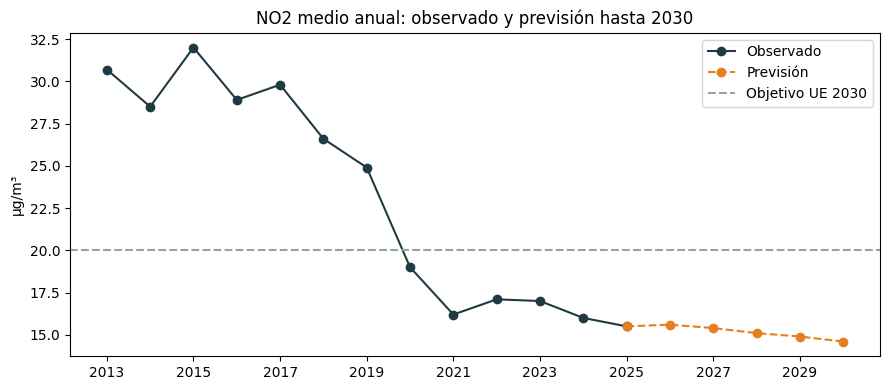

In [14]:
import io
from google.cloud import storage

plt.figure(figsize=(9, 4))
plt.plot(anual["anio"], anual["no2_medio"], marker="o", color="#203A43", label="Observado")

anios_prevision = [anual["anio"].iloc[-1]] + futuro["anio"].tolist()
valores_prevision = [anual["no2_medio"].iloc[-1]] + futuro["no2_previsto"].tolist()

plt.plot(anios_prevision, valores_prevision, marker="o", linestyle="--", color="#E67E22", label="Previsión")
plt.axhline(20, color="#8FA5A8", linestyle="--", label="Objetivo UE 2030")
plt.title("NO2 medio anual: observado y previsión hasta 2030")
plt.ylabel("µg/m³")
plt.legend()
plt.xticks(range(2013, 2031, 2))
plt.tight_layout()

buffer = io.BytesIO()
plt.savefig(buffer, format="png", dpi=300, bbox_inches="tight")

bucket = storage.Client().bucket("tfm_unir1")
bucket.blob("processed/figuras/no2_regresion_lineal.png").upload_from_string(
    buffer.getvalue(), content_type="image/png")

plt.show()

## 3. Modelo SARIMA mensual (2021-2025)

In [7]:
mensual = spark.sql ("""
    SELECT t.anio, t.mes, ROUND(AVG(a.concentracion),1) AS no2_medio
    FROM gold.fact_aire a
    JOIN gold.dim_tiempo t 
        ON a.id_tiempo = t.id_tiempo
    JOIN gold.dim_contaminante c 
        ON a.id_contaminante = c.id_contaminante
        WHERE c.nombre = 'NO2'
        AND t.anio BETWEEN 2021 and 2025
    GROUP by t.anio, t.mes
    ORDER BY t.anio, t.mes
    """).toPandas()

mensual

,anio,mes,no2_medio
0,2021,1,19.7
1,2021,2,15.6
2,2021,3,18.6
3,2021,4,15.8
4,2021,5,12.9
5,2021,6,13.4
6,2021,7,10.8
7,2021,8,12.1
8,2021,9,15.0
9,2021,10,18.6


In [8]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Convertimos la tala en una serie con fecha completa
mensual ["fecha"] = pd.to_datetime(dict(year=mensual["anio"], month=mensual["mes"], day=1))
serie = mensual.set_index ("fecha")["no2_medio"]
serie.index.freq = "MS"

# Entrenamiento: 2021-2014 (48 meses) / Test: 2025 (12 meses)
train_mensual = serie [:"2024-12-01"]
test_mensual = serie ["2025-01-01":]                            

### Usamos dos modelos SARIMAX distintos

No sabemos qué configuración del SARIMA funciona mejor con nuestros datos. Como vimos en los datos iniciales que hay un patrón estacional, usaremos dos que contemplan esa parte estacional (comparar cada mes con el mismo mes del año anterior) y se diferencias en como usan los meses anteriores:
    - SARIMA A: usa el valor del mes anterior.
    - SARIMA B: usa el cambio de un mes a otro y corrige su último error.

Para comparar los modelos usamos dos medidas de error sobre 2025:
- MAE (error absoluto medio): cuánto se equivoca en promedio cada mes
- MAPE (error porcentual medio): lo mismo, pero en porcentaje.
Cuanto más bajo el error, mejor predice el modelo.


In [9]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

# Referencia: predecir 2025 con los mismos meses de 2024
referencia = train_mensual ["2024-01-01":].values

#SARIMA A -- predice el valor usando el valor del mes pasado
modelo_a = SARIMAX(train_mensual, order=(1,0,0), seasonal_order=(0,1,1,12)).fit(disp=False)
pred_a = modelo_a.forecast(12) #predecimos1 año, 12 meses

#SARIMA B (airline) -- predice teniendo en cuenta los cambios mes a mes 
modelo_b = SARIMAX(train_mensual, order=(0,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
pred_b = modelo_b.forecast(12) #predecimos1 año, 12 meses

for nombre, prediccion in [("Referencia", referencia), ("SARIMA A", pred_a), ("SARIMA B", pred_b)]:
    mae  = mean_absolute_error(test_mensual, prediccion)
    mape = mean_absolute_percentage_error(test_mensual, prediccion) * 100
    print(nombre, "→ MAE:", round(mae, 2), "µg/m³ | MAPE:", round(mape, 1), "%")

/opt/conda/miniconda3/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


Referencia → MAE: 2.08 µg/m³ | MAPE: 13.1 %
SARIMA A → MAE: 1.75 µg/m³ | MAPE: 10.8 %
SARIMA B → MAE: 1.67 µg/m³ | MAPE: 10.4 %


/opt/conda/miniconda3/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


El SARIMA B tiene un MAE mas bajo. Ambos modelos mejoran la referencia. 

In [10]:
# Reentrenamos con todos los datos (2021-2025) para predecir hasta 2030
final_a = SARIMAX(serie, order=(1,0,0), seasonal_order=(0,1,1,12)).fit(disp=False)
final_b = SARIMAX(serie, order=(0,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)

# Predecimos de enero 2026 a diciembre 2030 (60 meses)
prev_a = final_a.forecast (60)
prev_b = final_b.forecast (60)

print("Promedio de los 12 meses en 2030:")
print("  SARIMA A:", round(prev_a ["2030"].mean(),1), "µg/m³")
print("  SARIMA B:", round(prev_b ["2030"].mean(),1),"µg/m³")

/opt/conda/miniconda3/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'
/opt/conda/miniconda3/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'


Promedio de los 12 meses en 2030:
  SARIMA A: 16.4 µg/m³
  SARIMA B: 14.5 µg/m³


El SARIMA B prevee 14,5 µg/m³ para 2030, casi igual que la regresión lineal (14,6),aunque son modelos distintos: uno usa datos anuales y el otro mensuales.

El SARIMA A predice qque el NO2 se mantendrá igual que en los ultimos años, mientras que el SARIMA B predice que seguirá bajando un poco cada año, como viene pasando desde 2021. 

Los tres modelos quedan por debajo del objetivo de 20 µg/m³.

In [11]:
# Nos quedamos entonces con SARIMA B y calculamos el intervalo de confianza

# Previsión con intervalo de confianza del 95 %
prevision = final_b.get_forecast(60)
intervalo = prevision.conf_int(alpha=0.05)

# Promedio de los meses de 2030
print("Intervalo para 2030 (95 %):")
print("  Mínimo:", round(intervalo.loc["2030"].iloc[:, 0].mean(), 1), "µg/m³")
print("  Máximo:", round(intervalo.loc["2030"].iloc[:, 1].mean(), 1), "µg/m³")

Intervalo para 2030 (95 %):
  Mínimo: 5.2 µg/m³
  Máximo: 23.9 µg/m³


**Conclusión:** Los modelos prevén que el NO2 medio de la ciudad se mantenga por debajo del objetivo europeo de 20 µg/m³ en 2030. La regresión lineal predice 14,6 µg/m³ y el SARIMA B, el modelo con menor error, 14,5 µg/m³.

El intervalo de confianza del SARIMA B (5,2-23,9 µg/m³) es amplio y su límite superior supera los 20 µg/m³. Por eso, aunque cumplir el objetivo es el escenario más probable, no puede asegurarse del todo.

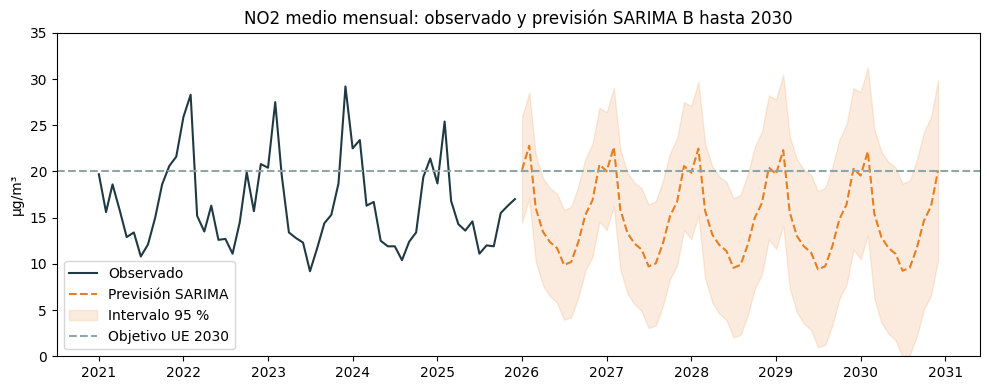

In [15]:
import io
from google.cloud import storage

plt.figure(figsize=(10, 4))
plt.plot(serie.index, serie, color="#203A43", label="Observado")
plt.plot(prev_b.index, prev_b, color="#E67E22", linestyle="--", label="Previsión SARIMA")
plt.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1],
                 color="#E67E22", alpha=0.15, label="Intervalo 95 %")
plt.axhline(20, color="#8FA5A8", linestyle="--", label="Objetivo UE 2030")
plt.title("NO2 medio mensual: observado y previsión SARIMA B hasta 2030")
plt.ylabel("µg/m³")
plt.legend()
plt.ylim(0, 35)
plt.tight_layout()

# Guardar en el bucket
buffer = io.BytesIO()
plt.savefig(buffer, format="png", dpi=300, bbox_inches="tight")
bucket = storage.Client().bucket("tfm_unir1")
bucket.blob("processed/figuras/no2_sarima_mensual.png").upload_from_string(
    buffer.getvalue(), content_type="image/png")

plt.show()

**Conclusión:** Los meses de invierno superan los 20 µg/m³, tanto en los datos reales como en la
previsión. No significa que no se cumpla el objetivo: el límite de 20 µg/m³ se
refiere a la media anual, no a cada mes.

La banda naranja se ensancha con los años: cuanto más lejos es la previsión,
mayor es la incertidumbre.

## 4. Guardar las predicciones en fact_prediccion

In [ ]:
# Armamos el dataframe de las predicciones

from datetime import date

# Regresión lineal: un valor por año
tabla_lineal = pd.DataFrame({
    "modelo": "regresion_lineal",
    "indicador": "no2",
    "horizonte": "2030",
    "granularidad": "anual",
    "fecha_ejecucion": date.today(),
    "fecha_prevista": pd.to_datetime(futuro["anio"].astype(str) + "-01-01").dt.date,
    "id_tiempo": None,
    "id_estacion": None,
    "valor_previsto": futuro["no2_previsto"],
    "valor_bajo": None,
    "valor_alto": None,
})

# SARIMA B: un valor por mes, con intervalo
intervalo_b = final_b.get_forecast(60).conf_int(alpha=0.05)
tabla_sarima = pd.DataFrame({
    "modelo": "sarima_b",
    "indicador": "no2",
    "horizonte": "2030",
    "granularidad": "mensual",
    "fecha_ejecucion": date.today(),
    "fecha_prevista": prev_b.index.date,
    "id_tiempo": None,
    "id_estacion": None,
    "valor_previsto": prev_b.round(1).values,
    "valor_bajo": intervalo_b.iloc[:, 0].round(1).values,
    "valor_alto": intervalo_b.iloc[:, 1].round(1).values,
})

# Juntamos las dos tablas
predicciones = pd.concat([tabla_lineal, tabla_sarima], ignore_index=True)
print(len(predicciones), "filas")
predicciones.head(7)

In [ ]:
# Guardamos en la GOLD

# Convertimos la tabla de pandas en una vista que spark.sql puede leer
# (sacamos id_tiempo e id_estacion porque están vacías; las ponemos como NULL en el SQL)
datos_pred = predicciones.drop(columns=["id_tiempo", "id_estacion"])

pd.DataFrame.iteritems = pd.DataFrame.items   # compatibilidad entre Spark y pandas
spark.createDataFrame(datos_pred).createOrReplaceTempView("predicciones")

spark.sql("""
    INSERT INTO TABLE gold.fact_prediccion
    SELECT modelo, indicador, horizonte, granularidad,
           CAST(fecha_ejecucion AS DATE),
           CAST(fecha_prevista AS DATE),
           CAST(NULL AS INT)    AS id_tiempo,
           CAST(NULL AS STRING) AS id_estacion,
           CAST(valor_previsto AS DOUBLE),
           CAST(valor_bajo AS DOUBLE),
           CAST(valor_alto AS DOUBLE), 
           CAST (NULL AS INT) AS id_distrito
    FROM predicciones
""")

spark.sql("SELECT modelo, COUNT(*) AS filas FROM gold.fact_prediccion GROUP BY modelo").show()